# GSB 5544 — Topic 11.1: Classification — What Every Score Measures — SOLUTION
*The target is a category now. Errors are counted, not measured in dollars, and one model produces a dozen
different scores. Each one is a ratio of counts from the same 2 × 2 table; this notebook defines each from that
table, computes it by hand, checks it with scikit-learn, and asks what it ignores.*

## The plan

| | | tools |
|---|---|---|
| **1. From regression to classification** | a categorical target; the KNN classifier votes; a prediction is a probability plus a threshold | `KNeighborsClassifier`, `predict`, `predict_proba` |
| **2. The confusion matrix** | four counts — TP, FP, FN, TN — and the choice of a *positive* class | `confusion_matrix` |
| **3. Accuracy and its baseline** | $(TP + TN)/n$; what the majority class alone would score | `accuracy_score` |
| **4. Precision, recall, specificity, NPV** | four ratios, each blind to one kind of error | `precision_score`, `recall_score`, `pos_label` |
| **5. F1** | the harmonic mean of precision and recall, and why not the ordinary mean | `f1_score` |
| **6. More than two classes** | one score per class, then macro and weighted averages | `classification_report` |
| **7. Probabilities and the threshold** | moving $t$ trades recall for precision; the tie at exactly 0.5 | `predict_proba`, a threshold loop |
| **8. Curves** | precision–recall and ROC; average precision and AUC | `precision_recall_curve`, `roc_curve`, `roc_auc_score` |
| **9. Scoring the probabilities** | log loss | `log_loss` |
| **10. Which score, when** | the cost of each error decides | |
| **11. Review questions** | | |

**Data:** the Palmer penguins (333 birds with complete measurements). Two-class question: predict a penguin's
**sex** from bill length, bill depth, flipper length and body mass. Three-class question: predict its
**species**. PA 11.1 asks the same things about tropical storms and Titanic passengers.

**Convention for the whole notebook.** Scores are computed on a **test set** the model did not see (a stratified
25 % split, `random_state=5544`), because that is what they are for. Every formula is identical on training
rows — PA 11.1 asks for training versions — the numbers are just more flattering there.

In [1]:
try:
    import palmerpenguins
except ImportError:                       # Colab does not have it; one-time install
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "palmerpenguins"], check=True)
    import palmerpenguins

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, precision_recall_curve, roc_curve, roc_auc_score,
                             average_precision_score, log_loss)

---
## 1. From regression to classification

Everything about the *recipe* is unchanged: `X`, `y`, split, create, `.fit`, `.predict`, evaluate. Two things
change because the target is a **category**:

1. **What the model outputs.** A class label — and, for most classifiers, a **probability for each class**.
   A $k$-nearest-neighbor *classifier* takes a majority vote among the $k$ nearest training rows, and its
   estimated probability of class $c$ is simply the share of neighbors in that class:
   $$\hat p(c \mid x) = \frac{\#\{\text{neighbors of } x \text{ in class } c\}}{k}.$$
   With $k = 10$ the only possible probabilities are $0, 0.1, \dots, 1$.
2. **How error is measured.** A prediction is either right or wrong; there is no "off by \$9,000". So every score
   is built from **counts** of right and wrong predictions, and RMSE is replaced by the dozen ratios below.

The sex question first: `y = 1` for female, `0` for male. Features are scaled because KNN measures distance.

In [2]:
penguins = palmerpenguins.load_penguins().dropna(subset=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "sex"])
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X = penguins[features]
y = (penguins["sex"] == "female").astype(int)          # 1 = female (the "positive" class), 0 = male

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=5544, stratify=y)
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=10))
knn.fit(X_train, y_train)

pred = knn.predict(X_test)                 # class labels, 0 or 1
prob = knn.predict_proba(X_test)[:, 1]     # column order = knn.classes_ = [0, 1]; take P(female)
print("classes_:", knn.classes_, "   test rows:", len(y_test), "   female share:", round(y_test.mean(), 3))
pd.DataFrame({"actual": y_test.values[:8], "predicted": pred[:8], "P(female)": prob[:8]})

classes_: [0 1]    test rows: 84    female share: 0.5


,actual,predicted,P(female)
0,0,0,0.1
1,1,0,0.3
2,0,1,0.7
3,1,1,0.9
4,1,1,0.9
5,1,1,1.0
6,0,0,0.1
7,1,1,0.8


✅ **Checkpoint 1.** (a) For a test penguin whose 10 nearest training penguins are 7 female and 3 male, what
does `predict_proba` return and what does `predict` return? (b) What is the smallest change to the neighbors
that flips the prediction? (c) Why must `predict_proba(...)[:, 1]` be read together with `knn.classes_`?

**Answer:** (a) `predict_proba` returns `[0.3, 0.7]` (P(male), P(female)) and `predict` returns `1`, female — the majority.
(b) Two neighbors switching from female to male makes it 5–5, a tie; three makes it 4–6 and the prediction
flips to male. (c) The columns are in the order of `classes_` (sorted labels, here `[0, 1]`), so column 1 is
P(class 1) = P(female) only because we coded female as 1. With string labels the order is alphabetical.

---
## 2. The confusion matrix

Pick a **positive class** — the one you are trying to detect (female here; "hurricane", "survived", "fraud",
"spam" elsewhere). Every test row then lands in one of four cells:

| | predicted **positive** | predicted **negative** |
|---|---|---|
| actually **positive** | **TP** true positive | **FN** false negative (a miss) |
| actually **negative** | **FP** false positive (a false alarm) | **TN** true negative |

with $TP + FP + FN + TN = n$. Two kinds of mistake — **misses** (FN) and **false alarms** (FP) — and every score
in this notebook is a way of weighing them. scikit-learn's `confusion_matrix(y_true, y_pred)` puts **actual
classes in rows and predicted classes in columns, in sorted label order**, so with labels `[0, 1]` the layout is
$\begin{pmatrix} TN & FP \\ FN & TP \end{pmatrix}$ — the positive class is the *second* row and column. Read it
once carefully; most classification mistakes in practice are reading this table the wrong way round.

In [3]:
cm = confusion_matrix(y_test, pred)                     # rows: actual 0, 1; columns: predicted 0, 1
TN, FP, FN, TP = cm.ravel()
print(cm)
print(f"TP = {TP}  FP = {FP}  FN = {FN}  TN = {TN}   (n = {TP + FP + FN + TN})")
pd.DataFrame(cm, index=["actual male (0)", "actual female (1)"], columns=["predicted male", "predicted female"])

[[37  5]
 [ 8 34]]
TP = 34  FP = 5  FN = 8  TN = 37   (n = 84)


,predicted male,predicted female
actual male (0),37,5
actual female (1),8,34


✅ **Checkpoint 2.** (a) In words, what happened to the 8 penguins in the FN cell? (b) If we had coded male as
the positive class instead, which numbers would move where? (c) Which single cell would a "predict female for
everyone" model drive to zero, and what would it do to the others?

**Answer:** (a) They are female penguins the model called male: misses. (b) TP and TN swap roles (37 ↔ 34) and so do FP and
FN (5 ↔ 8): a false alarm for "female" is a miss for "male". Every score below changes accordingly, which is why
`pos_label` matters. (c) FN would be 0 (no female is missed) — at the cost of FP = 42 (every male is a false
alarm), TP = 42, TN = 0. Recall 1, precision 0.5, accuracy 0.5.

---
## 3. Accuracy and its baseline

$$\text{accuracy} = \frac{TP + TN}{n}, \qquad \text{error rate} = 1 - \text{accuracy} = \frac{FP + FN}{n}.$$

Accuracy treats a miss and a false alarm as equally bad and ignores which class each row belongs to. That is fine
when the classes are balanced and the two errors cost the same. It is **misleading when one class is rare**: if
3 % of transactions are fraud, "never flag anything" has accuracy 0.97 while catching no fraud at all. Always
compare accuracy with the **majority-class baseline** — the accuracy of predicting the most common class for
every row — which is the larger of the two class shares.

In [4]:
accuracy = (TP + TN) / (TP + FP + FN + TN)
baseline = max(y_test.mean(), 1 - y_test.mean())        # predict the majority class for everyone
print(f"accuracy by hand = ({TP} + {TN}) / {len(y_test)} = {accuracy:.4f}")
print("accuracy_score  =", round(accuracy_score(y_test, pred), 4))
print("majority-class baseline =", round(baseline, 4))

accuracy by hand = (34 + 37) / 84 = 0.8452
accuracy_score  = 0.8452
majority-class baseline = 0.5


✅ **Checkpoint 3.** (a) The model is right about 84.5 % of test penguins versus a 50.0 % baseline. Suppose
instead the test set were 90 % male and the model scored 0.90 accuracy; what would you want to know before
being impressed? (b) Write the accuracy of the "predict female for everyone" model from Checkpoint 2(c) as a
fraction of the four cells.

**Answer:** (a) Whether it ever predicts "female": a model that always says male also scores 0.90 on that test set, so
0.90 may be the baseline, not an achievement. You would look at recall for the rare class (section 4). (b)
$(TP + TN)/n = (42 + 0)/84 = 0.5$ — exactly the female share, because every female is a TP and every male an FP.

---
## 4. Precision, recall, specificity, NPV

Four ratios, each conditioning on a different row or column of the table. Each is a *conditional proportion*,
and each is blind to one of the two error types.

| score | formula | reads as | ignores |
|---|---|---|---|
| **precision** (positive predictive value) | $\dfrac{TP}{TP + FP}$ | of the rows the model *called* positive, the share that are positive | misses (FN) |
| **recall** (sensitivity, true-positive rate) | $\dfrac{TP}{TP + FN}$ | of the rows that *are* positive, the share the model caught | false alarms (FP) |
| **specificity** (true-negative rate) | $\dfrac{TN}{TN + FP}$ | of the rows that *are* negative, the share the model left alone | misses (FN) |
| **negative predictive value** | $\dfrac{TN}{TN + FN}$ | of the rows the model *called* negative, the share that are negative | false alarms (FP) |

Two symmetries worth saying out loud. **Precision and recall both have TP on top**; precision divides by the
*predicted-positive column*, recall by the *actual-positive row*. And the last two scores are nothing new:
**specificity is the recall of the negative class** and **NPV is the precision of the negative class**. That is
exactly what scikit-learn's `pos_label=0` computes, and it is what PA 11.1 means by "precision for the
non-hurricane class". The **false-positive rate** is $FP/(FP + TN) = 1 - \text{specificity}$; it returns in the
ROC curve.

In [5]:
precision   = TP / (TP + FP)
recall      = TP / (TP + FN)
specificity = TN / (TN + FP)
npv         = TN / (TN + FN)
print(f"precision   = {TP} / ({TP} + {FP}) = {precision:.4f}    sklearn: {precision_score(y_test, pred):.4f}")
print(f"recall      = {TP} / ({TP} + {FN}) = {recall:.4f}    sklearn: {recall_score(y_test, pred):.4f}")
print(f"specificity = {TN} / ({TN} + {FP}) = {specificity:.4f}    sklearn: {recall_score(y_test, pred, pos_label=0):.4f}   (recall of class 0)")
print(f"NPV         = {TN} / ({TN} + {FN}) = {npv:.4f}    sklearn: {precision_score(y_test, pred, pos_label=0):.4f}   (precision of class 0)")

precision   = 34 / (34 + 5) = 0.8718    sklearn: 0.8718
recall      = 34 / (34 + 8) = 0.8095    sklearn: 0.8095
specificity = 37 / (37 + 5) = 0.8810    sklearn: 0.8810   (recall of class 0)
NPV         = 37 / (37 + 8) = 0.8222    sklearn: 0.8222   (precision of class 0)


Read them in context: *of the 39 penguins the model called female, 87.2 % are female* (precision); *of the 42
female penguins, 81.0 % were caught* (recall). Precision is the user's question ("when it says female, can I
trust it?"); recall is the auditor's ("how many did it miss?").

✅ **Checkpoint 4.** (a) A model raises its precision from 0.87 to 0.95 without changing TP. Which cell changed,
and in which direction? (b) Which two of the four scores add up to the whole actual-positive row, and which two to
the whole predicted-positive column? (Hint: write $1 - \text{recall}$ and $1 - \text{precision}$ as fractions.)
(c) A spam filter has recall 0.99 and precision 0.60. Describe the user's experience in one sentence.

**Answer:** (a) FP fell (fewer false alarms); precision depends only on TP and FP. (b) $\text{recall} + FN/(TP+FN) = 1$:
recall and the miss rate split the actual-positive row. $\text{precision} + FP/(TP+FP) = 1$: precision and the
false-discovery rate split the predicted-positive column. (c) Almost no spam reaches the inbox, but four of
every ten messages in the spam folder are legitimate — the user has to check the spam folder.

---
## 5. F1: one number from two

Precision and recall pull in opposite directions (section 7 shows the mechanism), so a single summary is useful.
The **F1 score** is their **harmonic mean**:

$$F_1 = \frac{2}{\dfrac{1}{\text{precision}} + \dfrac{1}{\text{recall}}} = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}} = \frac{2\,TP}{2\,TP + FP + FN}.$$

The last form (substitute the definitions and simplify) shows what F1 really is: true positives against *both*
kinds of error, with TN ignored entirely. **Why the harmonic mean and not the ordinary mean?** The harmonic mean
is dragged toward the smaller of the two numbers. With precision 1 and recall 0.1 the ordinary mean is a
respectable 0.55; the harmonic mean is $2(1)(0.1)/(1.1) = 0.18$, which is the honest verdict on a model that
misses 90 % of the positives. A high F1 requires *both* precision and recall to be high.

(A weighted version, $F_\beta$, counts recall $\beta$ times as important as precision: $F_2$ for screening
problems where misses are expensive, $F_{0.5}$ when false alarms are.)

In [6]:
f1_hand = 2 * precision * recall / (precision + recall)
f1_cells = 2 * TP / (2 * TP + FP + FN)
print(f"F1 from precision and recall = {f1_hand:.4f}   from the cells = {f1_cells:.4f}   sklearn: {f1_score(y_test, pred):.4f}")
print(f"ordinary mean of precision and recall = {(precision + recall) / 2:.4f}   (always >= the harmonic mean)")
print(f"F1 for the negative class (male): {f1_score(y_test, pred, pos_label=0):.4f}")

F1 from precision and recall = 0.8395   from the cells = 0.8395   sklearn: 0.8395
ordinary mean of precision and recall = 0.8407   (always >= the harmonic mean)
F1 for the negative class (male): 0.8506


✅ **Checkpoint 5.** (a) Compute F1 for the male class by hand from NPV = 0.822 and specificity = 0.881 and
check it against the output. (b) Two models: A has precision 0.9, recall 0.5; B has precision 0.7, recall 0.7.
Which has the higher F1, and is that the right choice for a medical screening test? (c) Why does F1 not involve
TN at all, and when is that a drawback?

**Answer:** (a) $2(0.822)(0.881)/(0.822 + 0.881) = 1.448/1.703 \approx 0.851$, which matches `f1_score(..., pos_label=0)`.
(b) A: $2(0.9)(0.5)/1.4 = 0.643$; B: $2(0.7)(0.7)/1.4 = 0.700$. B wins on F1, and for screening — where a miss
is far worse than a false alarm — B's higher recall is also the better choice; a problem that weighted misses
even more would use $F_2$ or just report recall. (c) F1 is about the positive class: TP against the errors
that touch positives (FN) or positive calls (FP). Correctly rejected negatives earn nothing. When the negative
class is the one that matters, compute F1 with `pos_label=0` — or report both, as PA 11.1 asks.

---
## 6. More than two classes

With three species the confusion matrix is 3 × 3 (rows actual, columns predicted, alphabetical). There is no
single "positive" class, so each score is computed **one class against the rest**: for class $c$, TP is the
diagonal cell, FN the rest of its row, FP the rest of its column. `classification_report` does this for every
class and then averages two ways:

- **macro average**: the plain mean of the per-class scores — every class counts equally, so a rare class with
  poor recall pulls it down;
- **weighted average**: each class weighted by its number of actual rows (`support`) — dominated by the common
  classes, close to accuracy.

Accuracy is still $\text{trace}/n$, the diagonal over the total.

In [7]:
y_species = penguins["species"]
Xs_train, Xs_test, ys_train, ys_test = train_test_split(X, y_species, test_size=0.25, random_state=5544, stratify=y_species)
knn3 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=10)).fit(Xs_train, ys_train)
pred3 = knn3.predict(Xs_test)

labels = knn3.classes_
print(pd.DataFrame(confusion_matrix(ys_test, pred3, labels=labels),
                   index=[f"actual {c}" for c in labels], columns=[f"pred {c}" for c in labels]))
print()
print(classification_report(ys_test, pred3, digits=3))

                  pred Adelie  pred Chinstrap  pred Gentoo
actual Adelie              37               0            0
actual Chinstrap            5              12            0
actual Gentoo               0               0           30

              precision    recall  f1-score   support

      Adelie      0.881     1.000     0.937        37
   Chinstrap      1.000     0.706     0.828        17
      Gentoo      1.000     1.000     1.000        30

    accuracy                          0.940        84
   macro avg      0.960     0.902     0.921        84
weighted avg      0.948     0.940     0.937        84



✅ **Checkpoint 6.** (a) From the matrix, compute Chinstrap recall and Adelie precision by hand and check them in
the report. (b) Why is Chinstrap precision 1.000 while its recall is only 0.706 — what did the model do with
the five Chinstraps it got wrong? (c) Macro-average recall is 0.902 and weighted-average recall is 0.940. Which
one would you report if the rare species were the one you cared about, and why?

**Answer:** (a) Chinstrap recall $= 12/(5 + 12 + 0) = 0.706$; Adelie precision $= 37/(37 + 5 + 0) = 0.881$. (b) Every
penguin the model *called* Chinstrap was a Chinstrap (no false alarms, precision 1), but five Chinstraps were
called Adelie — misses that show up as Chinstrap FN and as Adelie FP, which is why Adelie's precision is the
score that dropped. (c) The macro average: it gives Chinstrap (17 test birds) the same weight as Adelie (37), so
its 0.706 recall is visible; the weighted average lets the two well-classified common species hide it.

---
## 7. Probabilities and the threshold

A classifier that outputs probabilities is really two things: a **score** $\hat p$ and a **decision rule**
"predict positive if $\hat p \ge t$". The default $t = 0.5$ (predict the more likely class) is a choice, not a
law. Lowering $t$ calls more rows positive: TP and FP both rise, FN falls — **recall goes up, precision
usually goes down**, and the false-positive rate rises. Raising $t$ does the reverse. Recall and the
false-positive rate are *monotone* in $t$ (they can only fall as $t$ rises); precision tends to rise but need not
at every step.

> **scikit-learn's tie rule.** `predict` returns the class with the *largest* probability; when two classes tie
> at exactly 0.5 (possible whenever $k$ is even) it returns the **first** class in `classes_`, i.e. the negative
> class. So `predict()` is *not* the same as `predict_proba()[:, 1] >= 0.5` — the latter calls the 5–5 ties
> positive. Say which rule you used; PA 11.1's thresholds question is where this bites.

In [8]:
rows = []
for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    pred_t = (prob >= t).astype(int)                   # the decision rule at threshold t
    cm_t = confusion_matrix(y_test, pred_t, labels=[0, 1]); TN_t, FP_t, FN_t, TP_t = cm_t.ravel()
    rows.append({"threshold": t, "TP": TP_t, "FP": FP_t, "FN": FN_t, "TN": TN_t,
                 "precision": TP_t / max(TP_t + FP_t, 1), "recall": TP_t / (TP_t + FN_t), "FPR": FP_t / (FP_t + TN_t)})
pd.DataFrame(rows).round(3)

,threshold,TP,FP,FN,TN,precision,recall,FPR
0,0.1,42,20,0,22,0.677,1.000,0.476
1,0.3,39,7,3,35,0.848,0.929,0.167
2,0.5,37,5,5,37,0.881,0.881,0.119
3,0.7,32,3,10,39,0.914,0.762,0.071
4,0.9,24,0,18,42,1.000,0.571,0.000


In [9]:
ties = (prob == 0.5).sum()
print("test penguins with P(female) exactly 0.5:", ties)
print("predict() calls them:", np.unique(pred[prob == 0.5]), "   'prob >= 0.5' calls them: 1")
print(f"recall via predict(): {recall_score(y_test, pred):.4f}    via prob >= 0.5: {recall_score(y_test, (prob >= 0.5).astype(int)):.4f}")

test penguins with P(female) exactly 0.5: 3
predict() calls them: [0]    'prob >= 0.5' calls them: 1
recall via predict(): 0.8095    via prob >= 0.5: 0.8810


✅ **Checkpoint 7.** (a) Reading the table down the threshold column, state the direction of TP, FP and FN as
$t$ rises, and explain each from the decision rule. (b) At $t = 0.9$ precision is 1.0. Is this the best
threshold? (c) Precision at $t = 0.5$ differs between the table (0.881) and section 4 (0.872). Why?

**Answer:** (a) As $t$ rises fewer rows pass the rule, so TP and FP can only fall and FN can only rise (every row that stops
being called positive was either a TP that becomes an FN or an FP that becomes a TN). Hence recall and FPR fall
monotonically. (b) Only if false alarms are what you cannot afford: recall has dropped to 0.57, so 43 % of
females are missed. "Best" needs the costs of the two errors. (c) The ties: the table uses $\hat p \ge 0.5$,
which calls the 5–5 penguins female, while `predict()` calls them male. Different rule, different cells.

---
## 8. Curves: every threshold at once

Rather than one threshold, plot the trade-off over all of them.

**Precision–recall curve.** For each distinct value of $\hat p$ used as a threshold, plot (recall, precision).
With $k = 10$ there are at most eleven distinct probabilities, so the curve is a handful of points joined by
lines; `precision_recall_curve` returns the two arrays plus one extra endpoint (recall 0, precision 1) and the
thresholds that produced the rest. A model with no information gives a flat line at the positive share
(here 0.5); a perfect one hugs the top-right corner. **Average precision (AP)** summarizes the curve as the
precision averaged over recall levels (the area under it, step-wise).

**ROC curve.** Plot the true-positive rate (recall) against the **false-positive rate** $FP/(FP + TN)$ for each
threshold. The diagonal is random guessing; the top-left corner is perfect. The **area under the ROC curve
(AUC)** has a clean probabilistic meaning: *the probability that a randomly chosen positive row receives a
higher score than a randomly chosen negative row.* AUC = 0.5 is chance, 1 is perfect ranking.

Both curves describe the *scores*, before any threshold is chosen. The PR curve is the more informative of
the two when the positive class is rare, because precision reacts to the number of false alarms relative to the
(few) positives while the FPR barely moves.

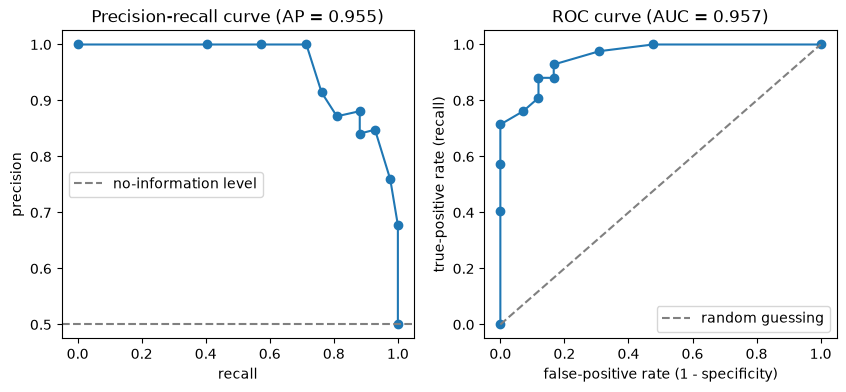

In [10]:
prec_c, rec_c, thr_c = precision_recall_curve(y_test, prob)
fpr_c, tpr_c, thr_r = roc_curve(y_test, prob)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(rec_c, prec_c, marker="o"); ax1.axhline(y_test.mean(), color="grey", linestyle="--", label="no-information level")
ax1.set_xlabel("recall"); ax1.set_ylabel("precision"); ax1.set_title(f"Precision-recall curve (AP = {average_precision_score(y_test, prob):.3f})"); ax1.legend()
ax2.plot(fpr_c, tpr_c, marker="o"); ax2.plot([0, 1], [0, 1], color="grey", linestyle="--", label="random guessing")
ax2.set_xlabel("false-positive rate (1 - specificity)"); ax2.set_ylabel("true-positive rate (recall)"); ax2.set_title(f"ROC curve (AUC = {roc_auc_score(y_test, prob):.3f})"); ax2.legend();

In [11]:
pd.DataFrame({"threshold": np.append(thr_c, np.nan), "precision": prec_c, "recall": rec_c}).round(3)

,threshold,precision,recall
0,0.0,0.500,1.000
1,0.1,0.677,1.000
2,0.2,0.759,0.976
3,0.3,0.848,0.929
4,0.4,0.841,0.881
5,0.5,0.881,0.881
6,0.6,0.872,0.810
7,0.7,0.914,0.762
8,0.8,1.000,0.714
9,0.9,1.000,0.571


✅ **Checkpoint 8.** (a) Which point on the PR curve corresponds to $t = 0.5$ in the table of section 7? (b)
Explain AUC = 0.957 in one plain sentence about two penguins. (c) A fraud model has AUC 0.95 and AP 0.30. How can
both be true, and which curve would you show the fraud team?

**Answer:** (a) The row with threshold 0.5: recall 0.881, precision 0.881. (b) Pick a random female and a random male from
the test set; 95.7 % of the time the model gives the female the higher P(female). (c) With fraud at 1 %, the
model can rank almost every fraud above almost every legitimate transaction (high AUC) while still flagging
many more legitimate transactions than frauds at any useful threshold, because there are so many legitimate
ones — so precision, and hence AP, stays low. Show the PR curve; it tells the team how many false alarms each
level of fraud recall costs.

---
## 9. Scoring the probabilities themselves

Every score so far judges *decisions*. **Log loss** judges the probabilities directly:

$$\text{log loss} = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log \hat p_i + (1 - y_i)\log(1 - \hat p_i)\Big],$$

where $\hat p_i$ is the predicted probability of the positive class. A confident correct prediction
($\hat p = 0.95$ when $y = 1$) costs $-\log 0.95 = 0.05$; a confident wrong one ($\hat p = 0.05$ when $y = 1$)
costs $-\log 0.05 = 3.0$; a shrug ($\hat p = 0.5$) costs $0.69$ either way. Lower is better; predicting the
positive share for every row gives the baseline. KNN can output exactly 0 or 1, which would cost infinity when
wrong, so scikit-learn clips the probabilities first. Log loss is what to optimize when the probabilities will be
*used* as probabilities (expected profit, ranking, pricing), not just thresholded.

In [12]:
print("log loss of the 10-NN probabilities:", round(log_loss(y_test, prob), 4))
print("log loss of 'predict the positive share for everyone':", round(log_loss(y_test, np.full(len(y_test), y_train.mean())), 4))

log loss of the 10-NN probabilities: 0.2662
log loss of 'predict the positive share for everyone': 0.6932


---
## 10. Which score, when

The right score is the one whose blind spot you can afford.

| situation | expensive error | lead with | watch |
|---|---|---|---|
| balanced classes, errors cost the same | either | accuracy | the baseline |
| screening (disease, fraud, hurricanes) | a **miss** (FN) | recall of the positive class | precision, or you drown in false alarms |
| acting on a positive is costly (sending a crew, blocking a card) | a **false alarm** (FP) | precision | recall, or you act on too few |
| you need one number for both | both | F1 (or $F_\beta$) | which class it was computed for |
| comparing models before choosing a threshold | — | AUC or AP | the threshold still has to be chosen |
| the probabilities will be used as probabilities | miscalibration | log loss | |

Three habits: always name the positive class and the threshold; always report the baseline next to accuracy;
and when a stakeholder cares about the *other* class, compute the same scores with `pos_label` switched —
specificity and NPV are not exotic, they are recall and precision from the other side.

---
## 11. Review questions

Short answers; a formula or a sentence each.

**Q1.** A test set has 200 rows, 40 positive. A model predicts 50 positives, of which 30 are correct. Fill in
the confusion matrix and compute accuracy, precision, recall, specificity and F1.

**Answer:** TP = 30, FP = 20, FN = 10, TN = 140. Accuracy $170/200 = 0.85$; precision $30/50 = 0.60$; recall $30/40 =
0.75$; specificity $140/160 = 0.875$; F1 $= 2(30)/(60 + 20 + 10) = 60/90 = 0.667$.

**Q2.** Write recall of the negative class and precision of the negative class in terms of TP, FP, FN, TN, and
name them.

**Answer:** Recall of the negative class $= TN/(TN + FP)$, the **specificity**; precision of the negative class $=
TN/(TN + FN)$, the **negative predictive value**. In scikit-learn: `recall_score(..., pos_label=0)` and
`precision_score(..., pos_label=0)`.

**Q3.** Show that $F_1 = 2TP/(2TP + FP + FN)$ from the harmonic-mean definition.

**Answer:** $F_1 = \dfrac{2PR}{P + R}$ with $P = \frac{TP}{TP+FP}$, $R = \frac{TP}{TP+FN}$. Numerator:
$\frac{2\,TP^2}{(TP+FP)(TP+FN)}$. Denominator: $\frac{TP(TP+FN) + TP(TP+FP)}{(TP+FP)(TP+FN)} =
\frac{TP(2TP + FP + FN)}{(TP+FP)(TP+FN)}$. Divide: $F_1 = \dfrac{2\,TP}{2TP + FP + FN}$.

**Q4.** A 10-NN classifier's `predict_proba` for a row is `[0.5, 0.5]`. What does `predict` return, and what
does the rule "positive if $\hat p \ge 0.5$" return?

**Answer:** `predict` returns the first class in `classes_` (the negative class, 0) — ties go to the first label. The
hand rule returns positive (1). The two rules differ exactly on the 5–5 ties, which is why precision and recall
"at 0.5" can come out differently depending on which one you used.

**Q5.** As the threshold rises from 0 to 1, which of recall, precision, FPR and accuracy are guaranteed to be
monotone, and in which direction?

**Answer:** Recall and FPR are non-increasing (raising $t$ can only remove predicted positives, so TP and FP can only fall).
Precision usually rises but is not guaranteed monotone (removing a TP can lower it). Accuracy is not monotone:
it typically rises then falls, peaking somewhere in the middle.

**Q6.** Interpret AUC = 0.80 without using the words "area" or "curve". Why might a model with AUC 0.80 still
be useless for a rare class at every threshold?

**Answer:** A randomly chosen positive row gets a higher score than a randomly chosen negative row 80 % of the time. If
positives are 1 % of rows, even a good ranking leaves hundreds of negatives scored above the typical positive, so
every threshold that catches most positives also flags many more negatives than positives: precision is low at
every operating point, which the PR curve (not the ROC curve) makes visible.

---
## The lines to keep

| | |
|---|---|
| **The table** | `confusion_matrix(y, pred)` → rows actual, columns predicted, sorted labels; for `[0, 1]`: `TN, FP, FN, TP = cm.ravel()` |
| **Accuracy** | $(TP + TN)/n$; compare with the majority baseline `max(share, 1 - share)` |
| **Precision / recall** | $TP/(TP + FP)$, $TP/(TP + FN)$; `precision_score`, `recall_score`; the other class with `pos_label=0` (= NPV, specificity) |
| **F1** | $2PR/(P + R) = 2TP/(2TP + FP + FN)$; harmonic, so both must be high; per class |
| **Multi-class** | `classification_report`: one row per class; macro = equal weight per class, weighted = by support |
| **Threshold** | `prob = model.predict_proba(X)[:, 1]`; `(prob >= t).astype(int)`; `predict()` breaks 0.5 ties toward class 0 |
| **Curves** | `precision_recall_curve(y, prob)` (+ `average_precision_score`), `roc_curve(y, prob)` (+ `roc_auc_score`) |
| **Probabilities as probabilities** | `log_loss(y, prob)` |

Course site: [https://gato365.github.io/gsb5544_instructor_learn_prep/](https://gato365.github.io/gsb5544_instructor_learn_prep/).